# Hubble's Constant Using Cosmic Ladder Method

Data: HST/WFC3 LMC Cepheids (Riess+ 2019), HST host-galaxy Cepheids (Riess+ 2016), Pantheon+SH0ES supernovae.

## 1. Calibrating the Cepheids

I've fit the Wesenheit period-luminosity relation m_W = a(log10 P - 1) + b0 for 70 LMC Cepheids. This gives the value of b0. b0 is the apparent magnitude of a 10 day time period Cepheid. Subtracting the distance modulus of LMC gives the absolute zero point.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import io

def load_vizier(path):
    with open(path) as f:
        lines=[l.strip().strip('"').strip() for l in f if l.strip()]
    lines=[l for l in lines if not l.startswith('#')]
    lines=[lines[0]]+lines[3:]
    return pd.read_csv(io.StringIO("\n".join(lines)),sep="\t",skipinitialspace=True)

def fit_pl(x,y,nsigma=3.0,max_iter=10):
    keep=np.ones(len(x),dtype=bool)
    for i in range(max_iter):
        coeffs=np.polyfit(x[keep],y[keep],1)
        res=y-np.polyval(coeffs,x)
        sigma=np.std(res[keep])
        new_keep=np.abs(res)<nsigma*sigma
        if np.array_equal(new_keep,keep):
            break
        keep=new_keep
    return coeffs[0],coeffs[1],sigma,keep.sum(),keep


lmc=load_vizier("calibdata.csv")

print(lmc.shape)
print(lmc.columns.tolist())

x=(lmc['logP']-1).values
y=(lmc['mWH']).values
slope,intercept,sigma,n,keep=fit_pl(x,y,nsigma=3)
res=y-np.polyval([slope,intercept],x)
print(f"slope(a)={slope},\nintercept(b)={intercept},\nstddeviation={sigma},\nnumber of stars kept={n}")


(70, 15)
['OGLE', 'RAJ2000', 'DEJ2000', 'Geo', 'logP', 'F555Wmag', 'e_F555Wmag', 'F814Wmag', 'e_F814Wmag', 'F160Wmag', 'e_F160Wmag', 'mWH', 'e_mWH', 'Nobs', 'Simbad']
slope(a)=-3.3441960436767735,
intercept(b)=12.66210995911649,
stddeviation=0.0766805295312732,
number of stars kept=69


Results:


a = -3.344


scatter σ = 0.077 mag


b0 = 12.662


Using LMC distance modulus μ_LMC = 18.477 (Pietrzyński+ 2019, eclipsing binaries) the absolute zero point is b = -5.815.

In [3]:
b_abs=intercept-18.477
print(b_abs)

-5.81489004088351


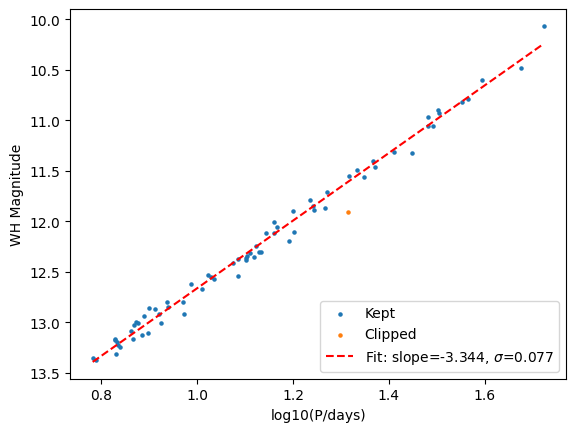

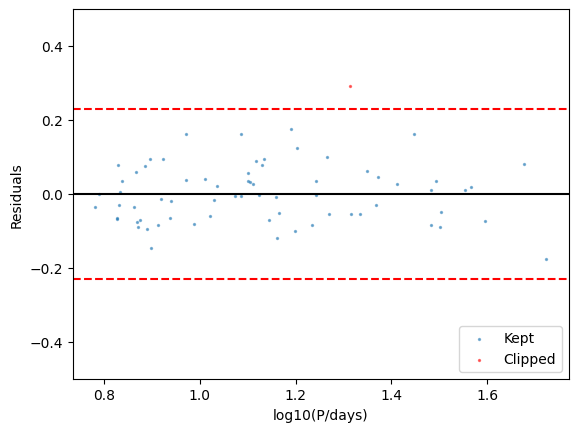

In [4]:
plt.scatter(lmc['logP'][keep],lmc['mWH'][keep],s=5,label='Kept',alpha=1)
plt.scatter(lmc['logP'][~keep],lmc['mWH'][~keep],s=5,label='Clipped',alpha=1)
plt.xlabel('log10(P/days)')
plt.ylabel('WH Magnitude')
plt.gca().invert_yaxis()
x_line = np.linspace(lmc['logP'][keep].min(), lmc['logP'][keep].max(), 100)
plt.plot(x_line,slope*(x_line -1)+intercept,'r--',label=f'Fit: slope={slope:.3f}, $\\sigma$={sigma:.3f}')
plt.legend(loc='lower right')
plt.show()

plt.scatter(lmc['logP'][keep],res[keep],s=2,label='Kept',alpha=0.5)
plt.scatter(lmc['logP'][~keep],res[~keep],s=2,color='red',label='Clipped',alpha=0.5)
plt.xlabel('log10(P/days)')
plt.ylabel('Residuals')
plt.ylim(-0.5, 0.5)
plt.axhline(y=0,   color='k',   ls='-',   lw=1.5)
plt.axhline(y=3*sigma,   color='red', ls='--',  lw=1.5)
plt.axhline(y=-3*sigma,  color='red',ls='--',   lw=1.5)
plt.legend(loc='lower right')
plt.show()

## 2. Distances to SN Ia host galaxies

Using the found values of a,b, the distance modulus of these distant galaxies are determined using the same formula.

μ = W - [a(log10 P − 1) + b]



In [6]:
host=load_vizier("hostdata.csv")
print(host.shape)
print(host.columns.tolist())
print(host['Gal'].value_counts())
host['Gal']=host['Gal'].str.strip()
host['logP']=np.log10(host['Per'])

#W = F160W − R × (V-I) and correcting the eq for higher metallicity(*0.2 per dex)
R=0.386 #SH0ES(2016)
host['mWH']=(host['F160W']-R*(host['V-I']))+0.2*(host['[O/H]']-8.65)

#dist mod
host['mu_i']=(host['mWH']-slope*(host['logP']-1)-b_abs)

def clipped_mean(v,nsigma=3.0,max_iter=10):
    keep=np.ones(len(v),dtype=bool)
    for i in range(max_iter):
        mu=np.mean(v[keep])
        s=np.std(v[keep])
        new_keep=np.abs(v-mu)<nsigma*s
        if np.array_equal(new_keep,keep):
            break
        keep=new_keep
    return mu,s,keep.sum()

rows=[]
for g in host['Gal'].unique():
    sub=host[host['Gal']==g]
    mu,s,n=clipped_mean(sub['mu_i'].values)
    rows.append({'Gal':g,'mu':mu,'scatter':s,'N':n,'err':s/np.sqrt(n),'d_Mpc':10**((mu-25)/5)})
mu_table=pd.DataFrame(rows)
print(mu_table)



(1486, 10)
['Gal', 'RAJ2000', 'DEJ2000', 'ID', 'Per', 'V-I', 'F160W', 'sigTot', '[O/H]', 'SimbadName']
Gal
M31      372
M101     251
N2442    141
N4258    139
N5584     83
N3447     80
N3370     63
N1448     54
N1309     44
N3972     42
N4536     33
N1365     32
U9391     28
N4639     25
N7250     22
N3021     18
N3982     16
N1015     14
N4038     13
N5917     13
N4424      3
Name: count, dtype: int64
      Gal         mu   scatter    N       err      d_Mpc
0    M101  29.054452  0.318163  250  0.020122   6.469793
1   N1015  32.455387  0.358606   14  0.095842  30.979709
2   N1309  32.452255  0.356720   44  0.053778  30.935061
3   N1365  31.276008  0.315398   32  0.055755  17.997059
4   N1448  31.218030  0.356591   54  0.048526  17.522904
5   N2442  31.458881  0.379259  141  0.031939  19.578356
6   N3021  32.434459  0.500309   18  0.117924  30.682571
7   N3370  32.022167  0.330615   63  0.041654  25.376598
8   N3447  31.887995  0.340521   80  0.038071  23.856071
9   N3972  31.588146  0.

## 3. Calibrating the SN Ia absolute magnitude

I matched 19 calibrator SNe to their hosts, averaging the duplicate entries for each SN.

M = m_b_corr - μ_host.

the μ value is on average 0.10 mag below the SH0ES values. Four hosts (N4639, N7250, N4038, N5917) differ from SH0ES by 0.2-0.4 mag and thus I excluded them.


In [7]:
pant=pd.read_csv('Pantheon+SH0ES.dat',sep=r'\s+')

print(pant.shape)
print(pant.columns)
print(pant['zHD'].describe())
print(pant['m_b_corr'].describe())

sub=pant[pant['IS_CALIBRATOR']==1]
print(len(sub))
print(len(sub['CID'].unique()))
sub=sub.groupby('CID', as_index=False)[['m_b_corr','zHD','CEPH_DIST']].mean()
print(len(sub))
with pd.option_context('display.max_rows', None):
  print(sub['CID'])

mapping={'2011fe':'M101','2009ig':'N1015','2002fk':'N1309','2012fr':'N1365','2001el':'N1448','2015F':'N2442','1995al':'N3021','1994ae':'N3370','2012ht':'N3447','2011by':'N3972','1998aq':'N3982','2007sr':'N4038','2012cg':'N4424','1981B':'N4536','1990N':'N4639','2007af':'N5584','2005cf':'N5917','2013dy':'N7250','2003du':'U9391'}

for i in mapping.keys():
  print(i)
  if i in list(sub['CID']):
    pass
  else:
    print(f'{i} is missing')
sub['Gal']=sub['CID'].map(mapping)
sub=sub.dropna(subset=['Gal'])
print(len(sub))
print(sub['CEPH_DIST'].describe())
print(sub)

merged=pd.merge(sub,mu_table,on='Gal')
print(len(merged))
merged['dmu']=merged['mu']-merged['CEPH_DIST']
print(merged)
print(np.mean(merged['dmu']))
print(np.std(merged['dmu']))

merged['M_mine']=merged['m_b_corr']-merged['mu']
merged['M_pp']=merged['m_b_corr']-merged['CEPH_DIST']
print('mean mine',np.mean(merged['M_mine']))
print('scatter mine',np.std(merged['M_mine']))
print('error mine',np.std(merged['M_mine'])/np.sqrt(len(merged)))
print('mean pp',np.mean(merged['M_pp']))
print('scatter pp',np.std(merged['M_pp']))
print('error pp',np.std(merged['M_pp'])/np.sqrt(len(merged)))
merged['weight']=1/(((merged['err'])**2)+((0.1)**2))
print('Weighted')
print((np.sum((merged['weight']*merged['M_mine'])))/np.sum(merged['weight']))
print((np.sum((merged['weight']*merged['M_pp'])))/np.sum(merged['weight']))
print('Error')
print(1/np.sqrt(np.sum(merged['weight'])))

#dropping the 4 galaxies with high deviation in mag
subtemp=merged[merged['Gal'] != 'N4639']
subtemp=subtemp[subtemp['Gal']!='N7250']
subtemp=subtemp[subtemp['Gal']!='N4038']
subtemp=subtemp[subtemp['Gal']!='N5917']
print((np.sum((subtemp['weight']*subtemp['M_mine'])))/np.sum(subtemp['weight']))
print((np.sum((subtemp['weight']*subtemp['M_pp'])))/np.sum(subtemp['weight']))
print(1/np.sqrt(np.sum(subtemp['weight'])))

(1701, 47)
Index(['CID', 'IDSURVEY', 'zHD', 'zHDERR', 'zCMB', 'zCMBERR', 'zHEL',
       'zHELERR', 'm_b_corr', 'm_b_corr_err_DIAG', 'MU_SH0ES',
       'MU_SH0ES_ERR_DIAG', 'CEPH_DIST', 'IS_CALIBRATOR', 'USED_IN_SH0ES_HF',
       'c', 'cERR', 'x1', 'x1ERR', 'mB', 'mBERR', 'x0', 'x0ERR', 'COV_x1_c',
       'COV_x1_x0', 'COV_c_x0', 'RA', 'DEC', 'HOST_RA', 'HOST_DEC',
       'HOST_ANGSEP', 'VPEC', 'VPECERR', 'MWEBV', 'HOST_LOGMASS',
       'HOST_LOGMASS_ERR', 'PKMJD', 'PKMJDERR', 'NDOF', 'FITCHI2', 'FITPROB',
       'm_b_corr_err_RAW', 'm_b_corr_err_VPEC', 'biasCor_m_b',
       'biasCorErr_m_b', 'biasCor_m_b_COVSCALE', 'biasCor_m_b_COVADD'],
      dtype='object')
count    1701.000000
mean        0.221229
std         0.249271
min         0.001220
25%         0.027730
50%         0.163750
75%         0.328680
max         2.261370
Name: zHD, dtype: float64
count    1701.000000
mean       19.083629
std         3.374499
min         9.745710
25%        16.036200
50%        20.076300
75%        2

## 4. Hubble flow and H₀

Using 434 unique non-calibrator SNe with 0.023 < z < 0.15:

μ = m - M, d = 10^((μ-25)/5) Mpc  
cz_eff = cz(1 + 0.775z) to account for the effect of cosmic acceleration

(q0 = -0.55 for flat ΛCDM, Ωm = 0.3).

Each SN gives H₀ = cz_eff/d

This H0 is averaged in log space.

496
434
count    434.000000
mean       0.058819
std        0.038304
min        0.023030
25%        0.029915
50%        0.041340
75%        0.075713
max        0.149400
Name: zHD, dtype: float64
count    434.000000
mean      17.359281
std        1.347999
min       15.205300
25%       16.263025
50%       17.000675
75%       18.346925
max       20.262400
Name: m_b_corr, dtype: float64


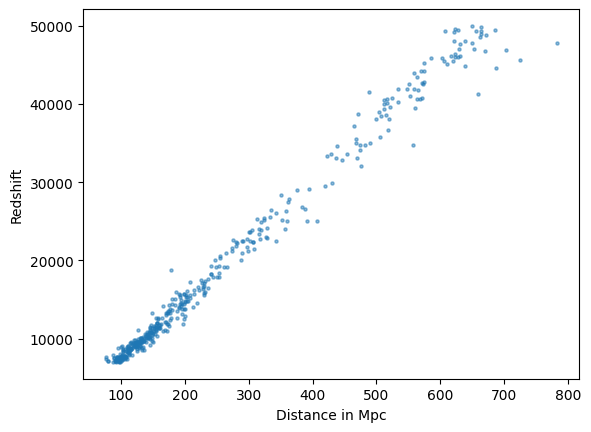

count    434.000000
mean      74.894600
std        5.327048
min       60.181324
25%       71.906766
50%       74.764733
75%       77.640581
max      105.325625
Name: H0, dtype: float64


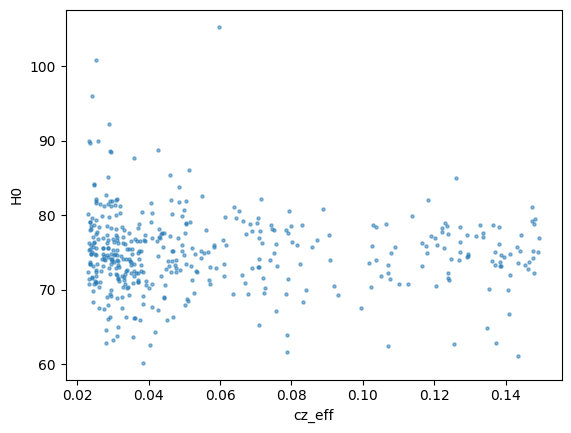

H0=74.624 (+/-) 1.392 km/s/Mpc


In [8]:
pantnew=pant[pant['IS_CALIBRATOR']==0]
pantnew=pantnew[pantnew['zHD']>0.023]
pantnew=pantnew[pantnew['zHD']<0.15]
print(len(pantnew))
pantnew=pantnew.groupby('CID', as_index=False)[['m_b_corr','zHD']].mean()
print(len(pantnew))
print(pantnew['zHD'].describe())
print(pantnew['m_b_corr'].describe())


M_19=-19.172858619273416
M_pant19=-19.260400214651398
M_15=-19.203937400384735
M_pant15=-19.251342362471163

pantnew['mu']=pantnew['m_b_corr']-M_15
pantnew['d']=10**((pantnew['mu']-25)/5)
pantnew['cz_eff']=299792.458*(pantnew['zHD'])*(1+(0.775*pantnew['zHD']))
pantnew['H0']=pantnew['cz_eff']/pantnew['d']
plt.scatter(pantnew['d'],pantnew['cz_eff'],s=5,alpha=0.5)
plt.xlabel('Distance in Mpc')
plt.ylabel('Redshift')
plt.show()
print(pantnew['H0'].describe())
pantnew['logH0']=np.log10(pantnew['H0'])
plt.scatter(pantnew['zHD'],pantnew['H0'],s=5,alpha=0.5)
plt.xlabel('cz_eff')
plt.ylabel('H0')
plt.show()
H0val,stddiv,no=clipped_mean(pantnew['logH0'].values)
err=(10**H0val)*np.log(10)*(stddiv/np.sqrt(no))
#adding up errors in quadrature (stat err,error in M,error in LMC dist)
errorbudget=np.sqrt((err)**2+(0.03040629202342474*0.46*(10**H0val))**2+(0.026*0.46*(10**H0val))**2)
print(f'H0={10**H0val:.3f} (+/-) {errorbudget:.3f} km/s/Mpc')



## Result

H0 = 74.6 ± 1.4 km/s/Mpc

Comparison:
Planck (CMB) : 67.4 km/s/Mpc
SH0ES : 73 km/s/Mpc

My result is 2.2% higher than that of SH0ES result.